In [1]:
from scipy.io import loadmat
import mat73

from tqdm.notebook import tqdm

import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib import colorbar as mbar
import seaborn as sns

from scipy.ndimage import gaussian_filter as smooth

from scipy.stats import zscore
from scipy.stats import sem
from scipy.stats import spearmanr as spearman

from scipy.stats import permutation_test

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

# Definitions

In [2]:
def m_plot(input_data, colors, error_method='sem', smooth_win=0, labels=[], plot_title='', XAxisTicks=[], figure_size=(8,3)):
    '''
    Args:
        input_data:   (N,M,T) matrix of input data, (Conditions,Samples,Timepoints)
        colors:       (N,4) matrix of colors for the generated plots in [R,G,B,FaceAlpha] format,
                      where N is the number of conditions. FaceAlpha in the scale=[0-255]
        error_method: variation metric ('sem' & 'std')
        smooth_win:   smoothing window
        
        labels:       (N,) list of labels for the generated plots, where N is the number of conditions
        plot_title:   title of the generated plot
        XAxisTicks:   (N,) vaetor of XAxisTicks
        figure_size:  two-item tuple containing width and height of the figure
    Returns:
        none
    '''

    colors = np.array(colors) / np.array(255)
    if not labels: labels=['']*len(input_data)
    XAxisTicks = np.array(XAxisTicks)
    if XAxisTicks.size==0: XAxisTicks = np.arange(0,input_data[0].shape[1])
    
    plt.figure(figsize=figure_size)
    for i,Cond in enumerate(input_data):
        data_ave = smooth(np.nanmean(Cond, axis=0), smooth_win)
        data_std = smooth(np.nanstd(Cond, axis=0), smooth_win)
        
        if error_method=='sem':
            error_up  = data_ave + (data_std / np.sqrt(Cond.shape[0]))
            error_low = data_ave - (data_std / np.sqrt(Cond.shape[0]))
        elif error_method=='std':
            error_up  = data_ave + data_std
            error_low = data_ave - data_std

        plt.fill_between(XAxisTicks, error_up, error_low, color=colors[i], label='_nolegend_')
        plt.plot(XAxisTicks, data_ave, color=colors[i,:3], lw=figure_size[0]*.5, label=labels[i])
    
    ylim = plt.ylim()
    plt.legend(frameon=False, fontsize=figure_size[0]*1.5)
    plt.title(plot_title, fontsize=figure_size[0]*1.8)
    # plt.rcParams.update({'font.size': figure_size[0]*.5})
    plt.tight_layout()


def comp_permute_p(vec1, vec2, permute_reps=100001):
    '''
    Args:
        vec1:         (N,) vector of data 1st distribution (Samples,)
        vec2:         (N,) vector of data 2nd distribution (Samples,)
        permute_reps: number of repetitions for the permutation process
    Returns:
        p_val: two-tailed p-value of the permutation process for [vec2 - vec1]
    '''

    vec1 = vec1[np.where((~np.isnan(vec1)))[0]]
    vec2 = vec2[np.where((~np.isnan(vec2)))[0]]

    def tmp_test_stat(x, y, axis):
        return np.nanmean(x, axis=axis) - np.nanmean(y, axis=axis)
    
    p_val = np.nan
    p_val = permutation_test(data=(vec2, vec1), statistic=tmp_test_stat, vectorized=True, axis=0, random_state=15, n_resamples=permute_reps).pvalue

    return p_val


def OutlierRemover(input_data):
    '''
    Args:
        input_data: (N,) vector of input data
    Returns:
        (M,) vector of data with outliers removed
    '''
    
    return np.array(input_data[abs(zscore(input_data))<3])

def compute_dprime(data1, data2):
    '''
    Args:
        data1: data for condition 1, shape (N,)
        data2: data for condition 2, shape (N,)
    Returns:
        d-prime value between the two data distributions, for data1-data2
    '''
    
    return (np.nanmean(data1) - np.nanmean(data2)) / np.sqrt(.5 * (np.nanvar(data1) + np.nanvar(data2)) )


# Load Data


In [36]:
FigDir = '../Results/figs_plv/'

tmp_FileDir = '../Results/results/PLV_YMT_v01.mat'
tmp_File = mat73.loadmat(tmp_FileDir)
# tmp_File.keys()

sig_thresh_1 = .05

# color
color_b, color_w, color_c = [100, 100, 100, 80], [222, 49, 99, 80], [50, 142, 110, 80]
color_b_n, color_w_n, color_c_n = np.array(color_b[:3])/255, np.array(color_w[:3])/255, np.array(color_c[:3])/255

num_conds= 3
freqs = np.arange(1,30.2,.2)


In [31]:
phlag_pval_0  = np.zeros((num_conds, freqs.shape[0])) * np.nan
phlag_pval_pi = np.copy(phlag_pval_0)

for iVar,item in enumerate(['p_val_diff_0_base', 'p_val_diff_0_wrong', 'p_val_diff_0_correct']):
    phlag_pval_0[iVar] = tmp_File[item]

for iVar,item in enumerate(['p_val_diff_pi_base', 'p_val_diff_pi_wrong', 'p_val_diff_pi_correct']):
    phlag_pval_pi[iVar] = tmp_File[item]

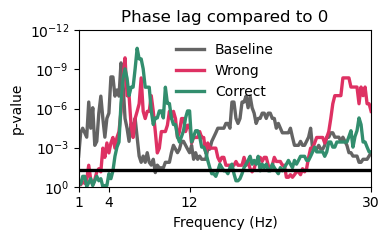

In [68]:
plot_xlim = [1,30]
plot_ylim = [1e-12, 1e0]
plot_xticks = [1,4,12,30]
plot_yticks = [min(plot_ylim),.4,.8,1.2,max(plot_ylim)]
figure_size = np.array((4,2.5)) * 1
plot_lw = figure_size[0]*.6
save_fig = 0

plt.figure(figsize=figure_size)
plt.plot(freqs, phlag_pval_0[0], color=color_b_n, lw=plot_lw, label="Baseline")
plt.plot(freqs, phlag_pval_0[1], color=color_w_n, lw=plot_lw, label="Wrong")
plt.plot(freqs, phlag_pval_0[2], color=color_c_n, lw=plot_lw, label="Correct")

plt.axhline(sig_thresh_1, color='k', ls='-', lw=figure_size[0]*.6)

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.yscale('log')
plt.ylim(plot_ylim)
plt.yticks([1e0,1e-3,1e-6,1e-9,1e-12])
plt.ylabel('p-value')
plt.gca().invert_yaxis()
plt.minorticks_off()

plt.legend(frameon=False, fontsize=figure_size[0]*2.5)
plt.title('Phase lag compared to 0')
plt.tight_layout()

if save_fig: plt.savefig(f'{FigDir}phase_lag_pval_0.svg')

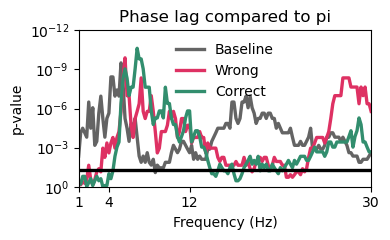

In [67]:
plot_xlim = [1,30]
plot_ylim = [1e-12, 1e0]
plot_xticks = [1,4,12,30]
plot_yticks = [min(plot_ylim),.4,.8,1.2,max(plot_ylim)]
figure_size = np.array((4,2.5)) * 1
plot_lw = figure_size[0]*.6
save_fig = 0

plt.figure(figsize=figure_size)
plt.plot(freqs, phlag_pval_pi[0], color=color_b_n, lw=plot_lw, label="Baseline")
plt.plot(freqs, phlag_pval_pi[1], color=color_w_n, lw=plot_lw, label="Wrong")
plt.plot(freqs, phlag_pval_pi[2], color=color_c_n, lw=plot_lw, label="Correct")

plt.axhline(sig_thresh_1, color='k', ls='-', lw=figure_size[0]*.6)

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.yscale('log')
plt.ylim(plot_ylim)
plt.yticks([1e0,1e-3,1e-6,1e-9,1e-12])
plt.ylabel('p-value')
plt.gca().invert_yaxis()
plt.minorticks_off()

plt.legend(frameon=False, fontsize=figure_size[0]*2.5)
plt.title('Phase lag compared to pi')
plt.tight_layout()

if save_fig: plt.savefig(f'{FigDir}phase_lag_pval_pi.svg')